# Urdu headline generation with mT5

CIS 6930 (Spring 2023) team project, Team 32 "Absolute Sum": Ammar Amjad, Mohammad Anas and
Michael Perez.

This notebook walks through the project: the task and the data, the token lengths that set
the model's limits, a problem with ROUGE on Urdu text, the baseline, and the results. The
model is trained by `python -m urdu_headlines.train`, which writes `outputs/metrics.json`.
The results shown here are read from `results/metrics.json`, the copy of that file from the
run reported in the README; the notebook does not train anything.

In [1]:
import json
from pathlib import Path

import pandas as pd
from rouge_score import rouge_scorer, tokenizers
from transformers import AutoTokenizer

from urdu_headlines.baseline import evaluate_baseline
from urdu_headlines.data import download, filter_short_titles, load_splits
from urdu_headlines.metrics import rouge_scores, tokenize
from urdu_headlines.plots import training_history
from urdu_headlines.preprocess import length_stats, token_lengths

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
# The run reported in the README; for a new run, use ROOT / "outputs" / "metrics.json".
METRICS_PATH = ROOT / "results" / "metrics.json"
SCORES = [f"{r}_{p}" for r in ("rouge1", "rouge2", "rougeL") for p in ("precision", "recall", "f1")]
pd.set_option("display.max_colwidth", 200)

## Task and data

The data is the Urdu part of XL-Sum (Hasan et al., 2021): BBC Urdu articles, each with its
title and a short summary written by the journalist, usually a single sentence. The model is
given the **summary** and has to write the **title**, so the task is headline generation for
a short news summary. The article body is not used.

XL-Sum is released under CC BY-NC-SA 4.0. It is downloaded from the Hugging Face Hub at run
time and is not part of this repository. As in the original notebook, examples whose title
has fewer than three words are dropped.

In [2]:
download(DATA_DIR)
everything = load_splits(DATA_DIR, min_title_words=0)
splits = filter_short_titles(everything)
pd.DataFrame(
    {
        "examples": {name: len(split) for name, split in everything.items()},
        "with 3+ word titles": {name: len(split) for name, split in splits.items()},
    }
)

,examples,with 3+ word titles
train,67665,67628
validation,8458,8454
test,8458,8454


In [3]:
splits["validation"].select(range(3)).to_pandas()[["summary", "title"]]

,summary,title
0,ایرانی اصلاح پسندوں نے اپنے صدارتی امیدوار کو نا اہل قرار دئے جانے پر شدید ردِ عمل ظاہر کیا ہے۔,ایران: اصلاح پسند ناراض
1,پاکستان کے وزیر دفاع خواجہ محمد آصف نے ملک میں پائے جانے والے اس تاثر کو رد کیا ہے کہ موجودہ فوجی قیادت سول حکومت کے کام میں بے جا مداخلت کر رہی ہے۔,فوج کی بے جا مداخلت کا تاثر درست نہیں: خواجہ آصف
2,ناسا کے ’ میگا راکٹ ‘ ایس ایل ایس ک ا کور سٹیج امریکہ کی ریاست نیو اورلینز کی فیکٹری سے تیار ہو کر باہر آچ کا ہے اور اب اس پر اہم تجربے کیے جائیں گے تاکہ لانچ کے لیے اس کے تیار ہونے یا نہ ہونے کا ...,امریکی خلابازوں کو چاند پر لے جانے والے ناسا کے نئے راکٹ کا پہلا مرحلہ مکمل


## Lengths in tokens

The original notebook derived its token limits from word counts: 11,230 + 10 for the input,
from the longest article in words (the article body, which is not the model input), and
36 + 2 for the title, from the longest title in words. The training script instead measures
the summaries and titles in mT5 tokens on the training split and uses the longest of each as
the limit, so no training example is truncated.

In [4]:
tokenizer = AutoTokenizer.from_pretrained("google/mt5-small")
summary_lengths = token_lengths(tokenizer, splits["train"]["summary"])
title_lengths = token_lengths(tokenizer, splits["train"]["title"])
long_titles = sum(n > 20 for n in title_lengths) / len(title_lengths)
print(f"{long_titles:.1%} of training titles are longer than 20 tokens")
pd.DataFrame({"summary": length_stats(summary_lengths), "title": length_stats(title_lengths)}).T

27.5% of training titles are longer than 20 tokens


,p50,p95,p99,max
summary,60,112,154,433
title,16,34,45,70


Generation needs its own limit. The original evaluation used mT5's default generation
length of 20 tokens, which cut off every title longer than that. The training script sets
`generation_max_length` to the longest training title plus one position for the decoder
start token.

## ROUGE on Urdu text

ROUGE compares a generated title with the reference: shared words (ROUGE-1), shared word
pairs (ROUGE-2) and the longest common word sequence (ROUGE-L). The `rouge-score` package,
which the ROUGE metric in Hugging Face `evaluate` also uses, lowercases the text and keeps
only `a-z` and `0-9` by default, so Urdu words are dropped and only Latin letters and digits
are compared. This title has neither, so it becomes an empty list of tokens and every score
is 0, even when the two strings are identical:

In [5]:
reference = "پانچ کروڑ کہاں گئے؟"
prediction = "پاچ کروڑ کہاں گئے؟"  # the first word is misspelled
print("default tokenizer:", tokenizers.DefaultTokenizer().tokenize(reference))
rouge_scorer.RougeScorer(["rouge1", "rougeL"]).score(reference, reference)

default tokenizer: []


{'rouge1': Score(precision=0.0, recall=0.0, fmeasure=0.0),
 'rougeL': Score(precision=0, recall=0, fmeasure=0)}

The original notebook noticed the zeros and switched to another ROUGE package that splits on
spaces. This project keeps `rouge-score` and gives it a tokenizer that splits on whitespace
(`urdu_headlines.metrics`). With one wrong word out of four, ROUGE-1 is 75:

In [6]:
print("whitespace tokenizer:", tokenize(reference))
rouge_scores([prediction], [reference])

whitespace tokenizer: ['پانچ', 'کروڑ', 'کہاں', 'گئے؟']


{'rouge1_precision': 75.0,
 'rouge1_recall': 75.0,
 'rouge1_f1': 75.0,
 'rouge2_precision': 66.6667,
 'rouge2_recall': 66.6667,
 'rouge2_f1': 66.6667,
 'rougeL_precision': 75.0,
 'rougeL_recall': 75.0,
 'rougeL_f1': 75.0,
 'empty_predictions': 0,
 'pred_words': 4.0,
 'ref_words': 4.0}

The original notebook also kept only ROUGE **recall**, the share of the reference's words
that appear in the output. Recall alone rewards long outputs, because a longer output covers
more of the reference. This project reports precision, recall and F1, with F1 as the main
number.

## Baseline: the summary as the title

The original baseline used the first three sentences of the summary, split on the Urdu full
stop "۔", as the title. Most summaries are a single sentence, so this is usually the whole
summary.

In [7]:
def sentence_count(summary):
    return len([s for s in summary.split("۔") if s.strip()])


for name in ("validation", "test"):
    counts = [sentence_count(summary) for summary in splits[name]["summary"]]
    one = sum(n == 1 for n in counts) / len(counts)
    longer = sum(n > 3 for n in counts)
    print(f"{name}: {one:.1%} of summaries are one sentence, {longer} have more than three")

baseline = {name: evaluate_baseline(splits[name]) for name in ("validation", "test")}
pd.DataFrame(baseline).T[SCORES + ["pred_words", "ref_words"]].round(2)

validation: 86.8% of summaries are one sentence, 32 have more than three
test: 87.0% of summaries are one sentence, 32 have more than three


,rouge1_precision,rouge1_recall,rouge1_f1,rouge2_precision,rouge2_recall,rouge2_f1,rougeL_precision,rougeL_recall,rougeL_f1,pred_words,ref_words
validation,14.02,52.27,21.40,5.85,22.35,8.94,12.45,46.78,19.05,33.44,8.28
test,14.16,52.00,21.53,6.03,22.66,9.17,12.61,46.60,19.20,33.03,8.32


Copying the summary covers about half of the title's words (ROUGE-1 recall), which is the
kind of number the original notebook reported. But a summary is about four times longer than
a title, so its precision, and with it the F1 score, is low.

## Results

`python -m urdu_headlines.train` fine-tunes `google/mt5-small` in fp32. After every epoch it
generates titles for the validation split; the epoch with the best ROUGE-L F1 is kept and
scored once on the test split. The settings of the run:

In [8]:
metrics = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
runtime = metrics["runtime"]
pd.Series(
    {
        **metrics["config"],
        "best epoch": metrics["best_checkpoint"]["epoch"],
        "device": runtime["device"],
        "training time (hours)": round(runtime["train_seconds"] / 3600, 2),
    }
).to_frame("value")

,value
epochs,4.0
max_steps,-1
learning_rate,0.000056
batch_size,8
eval_batch_size,8
weight_decay,0.01
seed,42
precision,fp32
max_source_length,433
max_target_length,70


### Test set

Both rows are scored on the same 8,454 test examples with the same metric.

In [9]:
test = {"summary as title": metrics["baseline"]["test"], "fine-tuned mT5-small": metrics["test"]}
pd.DataFrame(test).T[SCORES + ["pred_words", "ref_words"]].round(2)

,rouge1_precision,rouge1_recall,rouge1_f1,rouge2_precision,rouge2_recall,rouge2_f1,rougeL_precision,rougeL_recall,rougeL_f1,pred_words,ref_words
summary as title,14.16,52.00,21.53,6.03,22.66,9.17,12.61,46.60,19.20,33.03,8.32
fine-tuned mT5-small,28.47,29.11,27.40,13.34,13.35,12.62,27.30,27.91,26.28,8.70,8.32


The fine-tuned model scores higher than the baseline on every F1 score. Its precision and
recall are close to each other and its titles are about as long as the references
(`pred_words` and `ref_words` are mean lengths in words), while the baseline reaches its high
recall by copying a text about four times longer than a title.

### Training history

Validation scores and losses after each epoch. The training loss is the mean of the losses
logged during the epoch, with dropout active; the validation loss is measured at the end of
the epoch, without dropout. The gray line in each ROUGE panel is the summary-as-title
baseline on the validation split.

In [10]:
history = pd.DataFrame(metrics["history"]).set_index("epoch")
history = history.rename(columns={"loss": "validation_loss"})
history[["train_loss", "validation_loss", "rouge1_f1", "rouge2_f1", "rougeL_f1"]].round(3)

,train_loss,validation_loss,rouge1_f1,rouge2_f1,rougeL_f1
epoch,,,,,
1.0,3.257,2.155,25.284,11.002,24.279
2.0,2.573,2.071,26.298,11.796,25.243
3.0,2.443,2.027,26.672,11.964,25.633
4.0,2.389,2.017,26.854,12.063,25.818


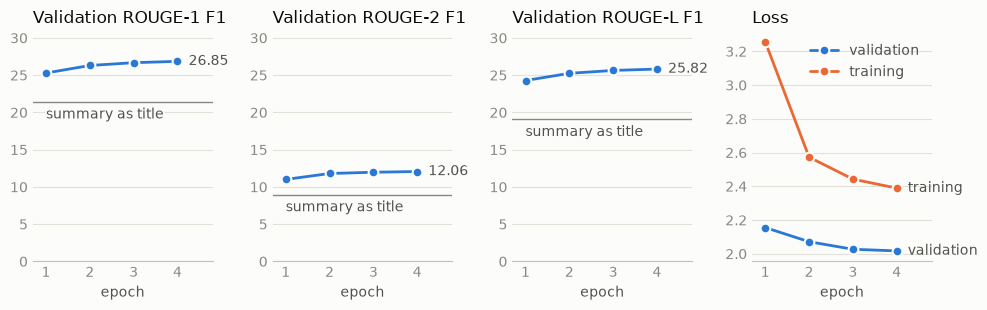

In [11]:
fig = training_history(metrics)

### Example predictions

A few random test examples with the reference title and the generated one.

In [12]:
pd.DataFrame(metrics["examples"])[["summary", "title", "prediction"]]

,summary,title,prediction
0,پاکستان کے صوبہ خیبر پختونخوا کے جنوبی ضلع ہنگو میں سڑک کنارے بم دھماکے میں عوامی نیشنل پارٹی کے ضلعی کونسلرسمیت دو افراد ہلاک اور دو زخمی ہوئے ہیں۔,ہنگو میں بم دھماکے میں اے این پی کے کونسلر سمیت دو ہلاک,ہنگو: عوامی نیشنل پارٹی کے ضلعی کونسلرسمیت دو ہلاک
1,امریکہ نے شام کے صدر بشارالاسد کا ماسکو کے دورے پر ’والہانہ استقبال‘ کرنے پر شدید مذمت کی ہے۔,بشار الاسد کا ماسکو میں ’پرتپاک استقبال،‘ امریکہ کی تنقید,شام کے صدر بشارالاسد کا ماسکو پر شدید مذمت
2,ریاست اتر پردیش میں فیض آباد کی ایک ذیلی عدالت نے ضلع بارہ بنکی میں گرام سبھا کی ز مین بالی وڈ سٹار امیتابھ بچن کو پٹے (لیز) پر دینے کا حکم کالعدم قرار دیا ہے۔,امیتابھ کے نام زمین کا پٹہ کالعدم,امیتابھ بچن کو پٹے پر دینے کا حکم کالعدم
3,صومالیہ کے دارالحکومت موغادیشو میں بموں اور بندوقوں کے حملوں میں کم از کم 19 افراد مارے گئے ہیں۔,صومالیہ میں خونریز حملوں میں 19 افراد ہلاک,موغادیشو میں بموں اور بندوقوں کے حملے میں 19 افراد مارے گئے
4,چین نے ایسے تیرہ ہزار افراد کی ایک فہرست جاری کی ہے جن کے متعلق اس کہنا ہے کہ انہیں جاپانی فوج نےانیس سو سینتیس کے ننجنگ قتل عام میں ہلاک کیا تھا۔,ننجنگ قتل عام کی فہرست جاری,چین نے تیرہ ہزار افراد کی فہرست جاری کر دی


## Notes

- Whitespace ROUGE counts exact word matches only. Inflected forms or spelling variants of a
  word count as different words, so the scores understate how close some titles are.
- The results come from one training run with one seed and greedy decoding.
- The validation F1 scores rose after every epoch, by less each time, so the best
  checkpoint is the last one.
- The numbers cannot be compared with the original notebook's. Those were ROUGE recall from
  a different package, with generation capped at 20 tokens, from a run whose saved output ends
  at epoch 4.76 of 8; the test split was never scored.
- The examples shown are from XL-Sum (BBC Urdu, CC BY-NC-SA 4.0).